# Scaling and learning rates

In this notebook, we'll train a neural network on a EEG dataset. The objective is to detect whether the eyes of the experimental subject are open or closed.  

First we do a couple of necessary imports and load the dataset. We also print the description.

In [2]:
import math
import tensorflow as tf
import numpy as np
import sklearn
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
plt.style.use("seaborn-v0_8")

# fetch data from openml.org
from sklearn.datasets import fetch_openml
data = fetch_openml('eeg-eye-state', cache=True)
print(data.DESCR)

**Author**: Oliver Roesler  
**Source**: [UCI](https://archive.ics.uci.edu/ml/datasets/EEG+Eye+State), Baden-Wuerttemberg, Cooperative State University (DHBW), Stuttgart, Germany  
**Please cite**: [UCI](https://archive.ics.uci.edu/ml/citation_policy.html)  

All data is from one continuous EEG measurement with the Emotiv EEG Neuroheadset. The duration of the measurement was 117 seconds. The eye state was detected via a camera during the EEG measurement and added later manually to the file after analyzing the video frames. '1' indicates the eye-closed and '0' the eye-open state. All values are in chronological order with the first measured value at the top of the data.

The features correspond to 14 EEG measurements from the headset, originally labeled AF3, F7, F3, FC5, T7, P, O1, O2, P8, T8, FC6, F4, F8, AF4, in that order.

Downloaded from openml.org.


When I first started working on this I couldn't get openml to work so I had to manually download the dataset. Both options are fine, but I will keep the former method for simplicity. Otherwise, the first lines of code would look like this.

The repository still contains the raw .csv file in case you encounter problems with openml as I did.

In [3]:
# import math
# import tensorflow as tf
# import numpy as np
# import sklearn
# import matplotlib.pyplot as plt
# import pandas as pd
# from sklearn.utils import shuffle
# plt.style.use("seaborn-v0_8")

# # Load data from the manually uploaded CSV file
# df_eeg = pd.read_csv('/content/eeg-eye-state.csv')

# data = {
#     'data': df_eeg.iloc[:, :-1].values, # All columns except the last one for features
#     'target': df_eeg.iloc[:, -1].values, # The last column for the target
#     'DESCR': "EEG Eye State Dataset (loaded manually because OPENML is not wokring)"
# }

# print(data['DESCR'])

Let's start examining the dataset. First question: how large is the dataset.

In [4]:
print("number of samples: {}".format(len(data["data"])))

number of samples: 14980


Next, we split off a training set and a validation set. Because there is not much data and we just want to compare different algorithms, we don't define a test set.

In [ ]:
X,y=sklearn.utils.shuffle(np.array(data["data"]), data["target"].astype('int')-1) #let's make sure the data is in random order
train_size=10000
X_train,X_val=X[:train_size],X[train_size:]
y_train,y_val=y[:train_size],y[train_size:]
X_train.shape,X_val.shape

((10000, 14), (4980, 14))

## Scaling

We continue inspecting the data. As I already know that the data takes continuous values with the values mainly in the same range, we can do a boxplot of the features.

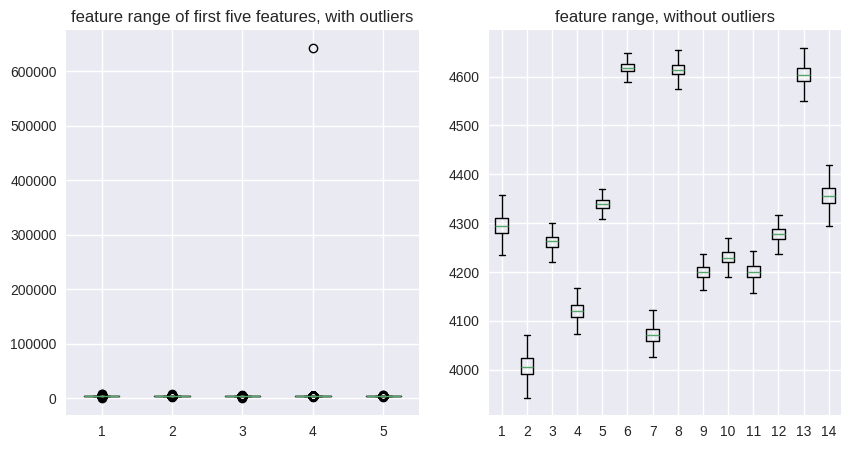

In [ ]:
_,axs=plt.subplots(1,2,figsize=(10,5))
axs[0].boxplot(X_train[:,:5])
axs[0].set_title("feature range of first five features, with outliers")
axs[1].boxplot(X_train,showfliers=False)
axs[1].set_title("feature range, without outliers")
plt.show()

We observe: there are substantial outliers and the data takes quite large values.

### Train NN
* We will use tensorflow, to define a ReLU-neural network for binary classification with two hidden layers, the first with 50 neurons, the second with 10 neurons.
* <code>tf.keras.losses.SparseCategoricalCrossentropy</code> as loss.
* We train the neural network for 30 epochs and pass along the validation set <code>validation_data=(X_val,y_val)</code> to <code>fit</code>.


In [ ]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Input((14,)),
  tf.keras.layers.Dense(50, activation = 'relu'),
  tf.keras.layers.Dense(10, activation = 'relu'),
  tf.keras.layers.Dense(2, activation = 'softmax')

])
loss_fn=tf.keras.losses.SparseCategoricalCrossentropy()
model.compile(loss=loss_fn, metrics=['accuracy'])

history=model.fit(X_train, y_train, epochs=30,validation_data=(X_val,y_val))

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4984 - loss: 159.5840 - val_accuracy: 0.4522 - val_loss: 27.0507
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5039 - loss: 62.9267 - val_accuracy: 0.5470 - val_loss: 67.4576
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5126 - loss: 58.2214 - val_accuracy: 0.5470 - val_loss: 37.1916
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5001 - loss: 41.9739 - val_accuracy: 0.5470 - val_loss: 44.5151
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4938 - loss: 29.7484 - val_accuracy: 0.5402 - val_loss: 7.6529
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4861 - loss: 19.0438 - val_accuracy: 0.5470 - val_loss: 10.5834
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5106 - loss: 8.7404 - val_accuracy: 0.5470 - val_loss: 1.3857
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5507 - loss: 0.6915 - val_

What happened? Obviously, the model performs not well, not at all. The reason: When the weights are initialised at the beginning of training it is expected that the data has values more or less in the range $[-1,1]$. Our data, however, takes much larger values. Because of that the neural network starts training in a sort of off-balance state and then takes a very long while moving away from there (if that happens at all). We'll rectify that by scaling the data. We use <code>sklearn.preprocessing.StandardScaler</code>, a method of *scikit-learn*.

What does <code>StandardScaler</code> do? First, it ensures that the data has mean 0 by substracting the mean from every sample. Then the data is multiplied by a factor so that the variance becomes 1. Thus, larger values than 1 are possible, but mostly the values range from -1 to 1. Let's have a look at the boxplots again.

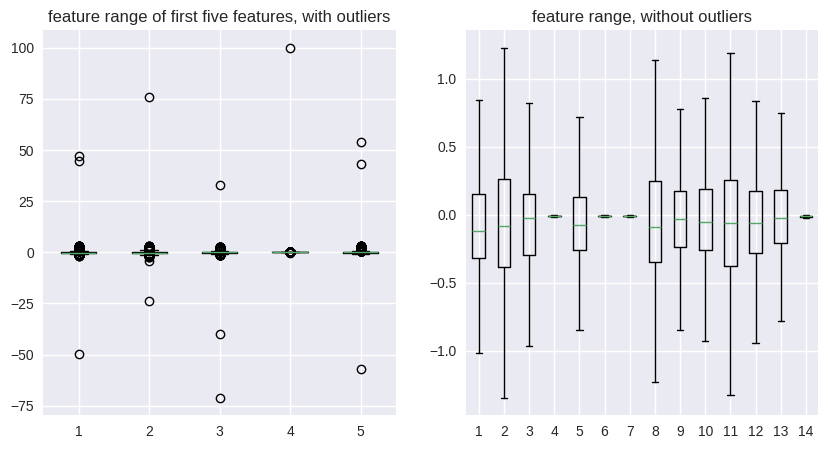

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) # we need to fit, to learn the mean and the variance
X_val_scaled=scaler.transform(X_val) # the validation/test set is only transformed, not fit

### plotting
_,axs=plt.subplots(1,2,figsize=(10,5))
axs[0].boxplot(X_train_scaled[:,:5])
axs[0].set_title("feature range of first five features, with outliers")
axs[1].boxplot(X_train_scaled,showfliers=False)
axs[1].set_title("feature range, without outliers")
plt.show()



### Train with scaling

In [ ]:
### insert your code here ###

loss_fn=tf.keras.losses.SparseCategoricalCrossentropy()
model.compile(loss=loss_fn, metrics=['accuracy'])

history=model.fit(X_train_scaled, y_train, epochs=30,validation_data=(X_val_scaled,y_val))

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5817 - loss: 0.6741 - val_accuracy: 0.6287 - val_loss: 0.6374
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6484 - loss: 0.6239 - val_accuracy: 0.6622 - val_loss: 0.6035
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6818 - loss: 0.5908 - val_accuracy: 0.6962 - val_loss: 0.5735
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7191 - loss: 0.5547 - val_accuracy: 0.7361 - val_loss: 0.5447
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7467 - loss: 0.5244 - val_accuracy: 0.7430 - val_loss: 0.5222
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7738 - loss: 0.4895 - val_accuracy: 0.7618 - val_loss: 0.4974
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7785 - loss: 0.4756 - val_accuracy: 0.7693 - val_loss: 0.4817
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7846 - loss: 0.4611 - val_accuracy: 0.

Much better!

## Learning rates

Next, we'll see how learning rates can be set. So far, we had always used the default values for the optimiser. The optimiser is specified when calling <code>compile</code> on a model. If we just want to choose between different optimisers without setting any optimiser specific parameters, we can prescribe the optimiser by passing a string:

<code>mode.compile(loss=loss_fn, metrics=['accuracy'],optimizer="SGD")  # stochastic gradient descent</code>

or

<code>mode.compile(loss=loss_fn, metrics=['accuracy'],optimizer="Adam")  # Adam optimiser</code>

As we want set a learning rate, however, we actually need to instantiate an optimiser object:

<code>my_SGD=tf.keras.optimizers.SGD(learning_rate=0.42)
mode.compile(loss=loss_fn, metrics=['accuracy'],optimizer=my_SGD)</code>

### Training with different learning rates
* For each of the learning rates $[0.01,0.1,1]$ we train a neural network of the same type as above (ie, two hidden layers with 50 and 10 neurons etc), again for 30 epochs each.
* We use the <code>history</code> object returned by <code>fit</code> to plot the three losses (for the different learning rates) in the same plot.
* Lastly, we plot also the validation loss.



In [ ]:
learning_rates = [0.01, 0.1, 1.0]
histories = {}

for lr in learning_rates:
  my_SGD=tf.keras.optimizers.SGD(learning_rate=lr)
  model.compile(loss=loss_fn, metrics = ['accuracy'], optimizer = my_SGD)

  history = model.fit(X_train_scaled, y_train, epochs=30, validation_data=(X_val_scaled, y_val))
  histories[lr] = history

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8665 - loss: 0.3132 - val_accuracy: 0.8279 - val_loss: 7.7556
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8544 - loss: 0.3219 - val_accuracy: 0.8181 - val_loss: 7.5815
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8702 - loss: 0.3072 - val_accuracy: 0.8398 - val_loss: 7.0674
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8705 - loss: 0.2967 - val_accuracy: 0.8518 - val_loss: 6.9874
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8754 - loss: 0.2862 - val_accuracy: 0.8480 - val_loss: 6.6342
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8752 - loss: 0.2896 - val_accuracy: 0.8486 - val_loss: 6.4090
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8741 - loss: 0.2899 - val_accuracy: 0.8470 - val_loss: 6.3534
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8750 - loss: 0.2935 - val_accuracy: 0.

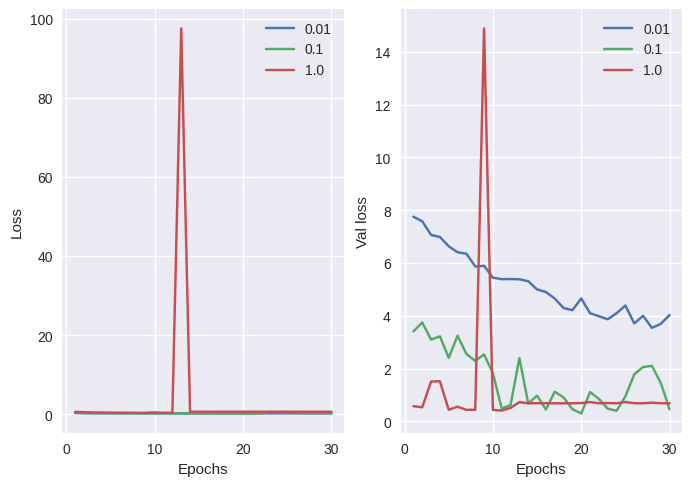

In [ ]:
_, axs = plt.subplots(1, 2)

epochs = range(1, 31)
for i in learning_rates:
  axs[0].plot(epochs, histories[i].history['loss'], label = f'{i}')
  axs[1].plot(epochs, histories[i].history['val_loss'], label=f'{i}')

axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend()

axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Val loss')
axs[1].legend()


It looks like big values for the learning rate are difficult to manage and yield inconsistent results. On the other side, small learning rates are simply too slow to be useful.